# Plotting of figures in Python (Ulcerative Colitis)

This notebook is used to plot all figures for Smillie that were created in Python.

**NOTE:**
Before running this notebook, you need to run "Visualization Smillie R".

**INPUT:**
- counts_corr.csv.gz
- interactions_f_s.csv
- interactions_f_r.csv
- interactions_a_s.csv
- interactions_a_r.csv
- interactions_e_s_l.csv
- interactions_e_r_r.csv
- interactions_rho_s.csv
- interactions_rho_r.csv

**FIGURES:**
- 2e (Main Fig.)
- 2f (Main Fig.)
- 2g (Main Fig.)
- 2h (Main Fig.)
- 4c (Sup. Fig.)
- 4e (Sup. Fig.)

## Import

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
from scipy.stats import ttest_ind
import statsmodels.stats.multitest as multi

In [2]:
input_dir = "./pdata/"

In [3]:
df_f_s   = pd.read_csv(input_dir + "interactions_f_s.csv", index_col=0)
df_f_r   = pd.read_csv(input_dir + "interactions_f_r.csv", index_col=0)
df_a_s   = pd.read_csv(input_dir + "interactions_a_s.csv", index_col=0)
df_a_r   = pd.read_csv(input_dir + "interactions_a_r.csv", index_col=0)
df_e_s_l = pd.read_csv(input_dir + "interactions_e_s_l.csv", index_col=0)
df_e_r_r = pd.read_csv(input_dir + "interactions_e_r_r.csv", index_col=0)
df_rho_s = pd.read_csv(input_dir + "interactions_rho_s.csv", index_col=0)
df_rho_r = pd.read_csv(input_dir + "interactions_rho_r.csv", index_col=0)

In [4]:
# Read counts data
counts = pd.read_csv(f"{input_dir}counts_corr.csv.gz", compression="gzip")
counts.set_index('gene_symbol', inplace=True)
counts.index.name = None

In [5]:
# Read cell annotations
cells = pd.read_csv(f"{input_dir}anno_cells_corr.txt", sep="\t")
cells.set_index('cell_ID', inplace=True)
cells.index.name = None
cells.rename(columns={'cell_ID.1': 'cell_ID'}, inplace=True)

## Figure 2e/f

In [6]:
def plot_and_ttest(df, interaction_name, label, ax, y_axis_label):
    subset_df = df.loc[df.index == interaction_name].T
    subset_df.columns = ["Value"]
    subset_df["Condition"] = ["Healthy" if "Healthy" in index else "Colitis" for index in subset_df.index]

    group1 = subset_df[subset_df['Condition'] == 'Healthy']['Value']
    group2 = subset_df[subset_df['Condition'] == 'Colitis']['Value']
    t_stat, p_value = ttest_ind(group1, group2)

    sns.boxplot(x='Condition', y='Value', hue='Condition', data=subset_df,
                palette={"Colitis": "#7C001F", "Healthy": "#7AC5CD"},
                boxprops=dict(alpha=0.70), showfliers=False, legend=False, ax=ax)
    sns.swarmplot(x='Condition', y='Value', data=subset_df, color='.25', size=14, ax=ax)

    ax.set_title(f"{label}", fontsize=20)

    # y-limits with space above the highest data point for the p-value text
    upper_margin = max(subset_df['Value']) * 0.15
    upper_limit = max(subset_df['Value']) + upper_margin
    lower_margin = max(subset_df['Value']) * 0.05
    lower_limit = min(subset_df['Value']) - lower_margin
    ax.set_ylim(bottom=lower_limit, top=upper_limit)

    ax.text(0.5, upper_limit - (upper_margin / 2), f"p-val: {round(p_value, 3)}",
            ha='center', fontsize=18)

In [7]:
def plot_interaction(interaction_name_variable, df_f_s, df_f_r, df_rho_s, df_rho_r, df_a_s, df_a_r, df_e_s_l, df_e_r_r):
    # Split into sender and receiver parts
    sender_info, receiver_info = interaction_name_variable.split('_')
    sender, sender_ligand = sender_info.split(':')
    receiver, receiver_receptor = receiver_info.split(':')

    # Panel titles
    labels_dict = {
        'f_s': f"{sender}",
        'f_r': f"{receiver}",
        'rho_s': f"{sender}",
        'rho_r': f"{receiver}",
        'a_s': f"{sender}: {sender_ligand}",
        'a_r': f"{receiver}: {receiver_receptor}",
        'e_s_l': f"{sender}: {sender_ligand}",
        'e_r_r': f"{receiver}: {receiver_receptor}"
    }

    # y-axis labels
    y_axis_labels = {
        'f_s': "sender",
        'f_r': "receiver",
        'rho_s': "cell type abundance",
        'rho_r': "cell type abundance",
        'a_s': "active fraction",
        'a_r': "active fraction",
        'e_s_l': "mean normalized expression in active fraction",
        'e_r_r': "mean normalized expression in active fraction"
    }

    fig, axes = plt.subplots(1, 8, figsize=(72, 9))

    dfs = [df_f_s, df_f_r, df_rho_s, df_rho_r, df_a_s, df_a_r, df_e_s_l, df_e_r_r]
    label_keys = ['f_s', 'f_r', 'rho_s', 'rho_r', 'a_s', 'a_r', 'e_s_l', 'e_r_r']

    for ax, df, label_key in zip(axes, dfs, label_keys):
        plot_and_ttest(df, interaction_name_variable, labels_dict[label_key], ax, y_axis_labels[label_key])
        ax.set_ylabel(y_axis_labels[label_key], fontsize=18)

    plt.tight_layout()
    plt.show()

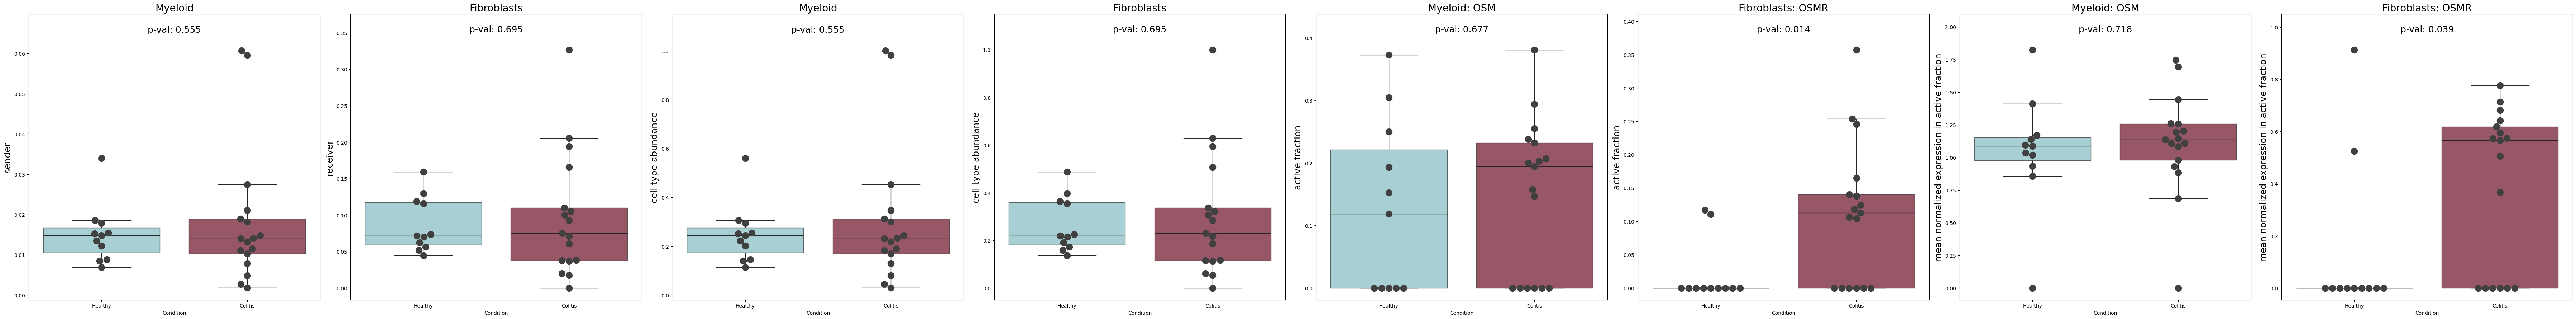

In [8]:
interaction_name_variable = "Myeloid:OSM_Fibroblasts:OSMR"
plot_interaction(interaction_name_variable, df_f_s, df_f_r, df_rho_s, df_rho_r, df_a_s, df_a_r, df_e_s_l, df_e_r_r)

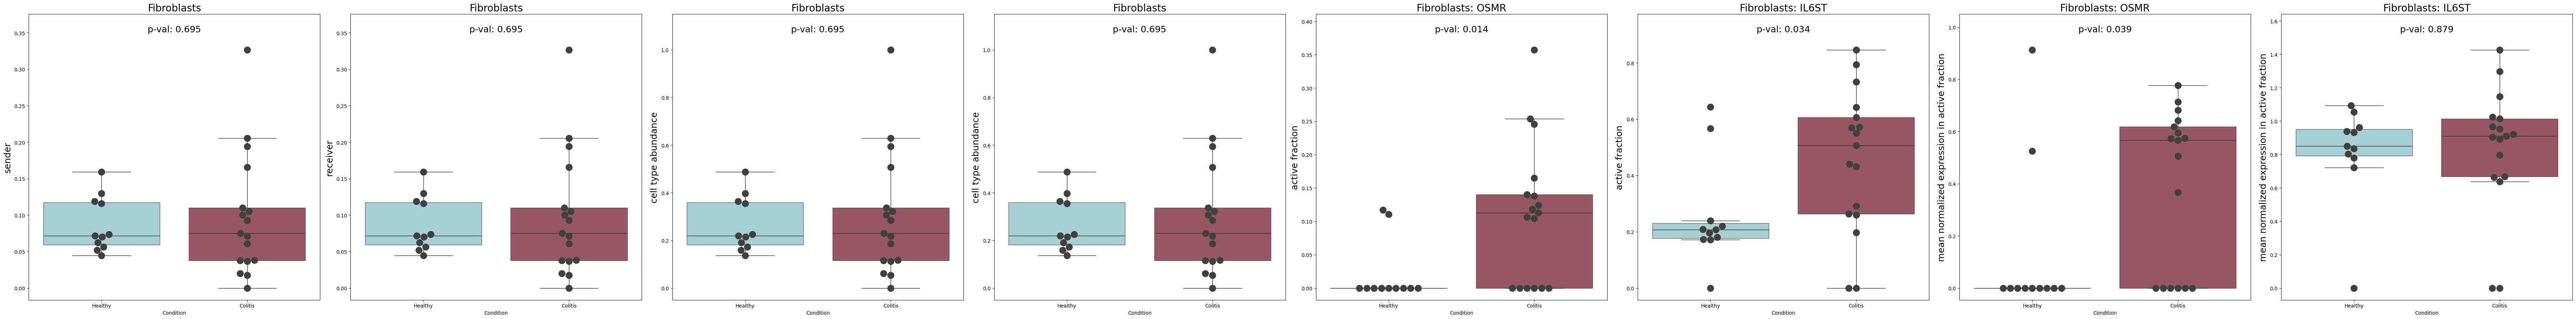

In [9]:
interaction_name_variable = "Fibroblasts:OSMR_Fibroblasts:IL6ST"
plot_interaction(interaction_name_variable, df_f_s, df_f_r,df_rho_s, df_rho_r, df_a_s, df_a_r, df_e_s_l, df_e_r_r)

/home/fsalcher/miniconda3/lib/python3.10/site-packages/seaborn/categorical.py:3399: UserWarning: 35.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/tmp/ipykernel_35603/747783824.py:22: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(bottom=lower_limit, top=upper_limit)
/home/fsalcher/miniconda3/lib/python3.10/site-packages/seaborn/categorical.py:3399: UserWarning: 35.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/home/fsalcher/miniconda3/lib/python3.10/site-packages/seaborn/categorical.py:3399: UserWarning: 35.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/tmp/ipykernel_35603/747783824.py:22: UserWarning: Attempting to set identical low and 

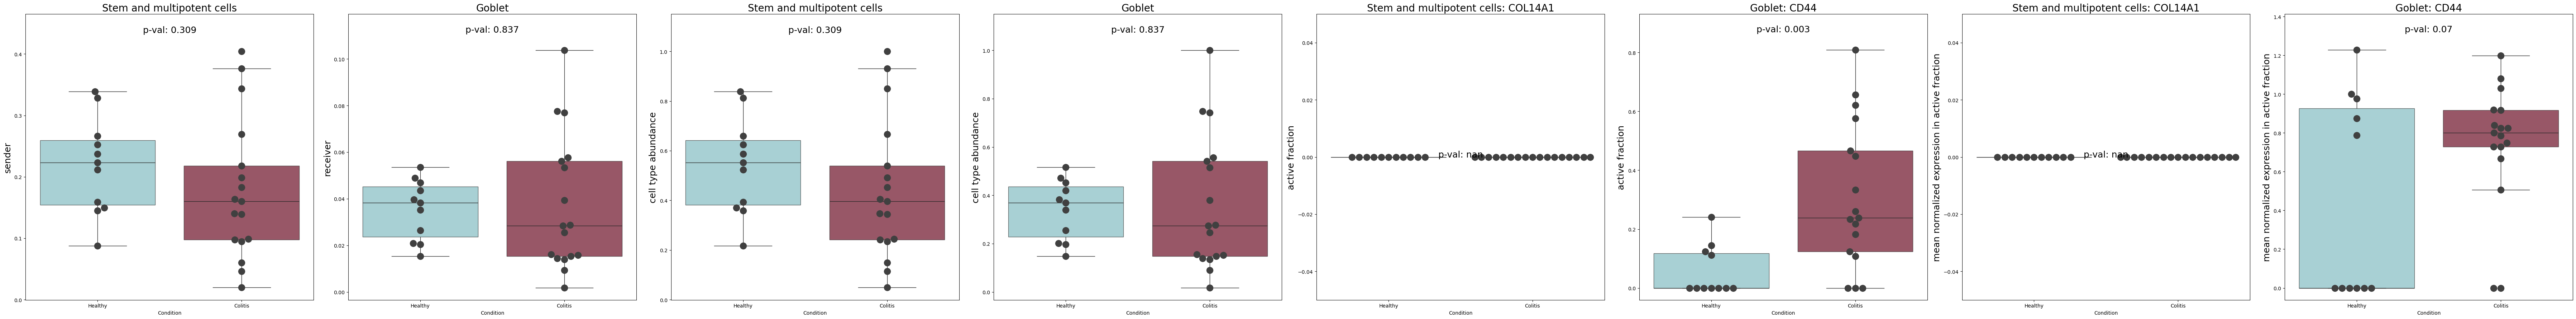

In [10]:
interaction_name_variable = "Stem and multipotent cells:COL14A1_Goblet:CD44"
plot_interaction(interaction_name_variable, df_f_s, df_f_r, df_rho_s, df_rho_r, df_a_s, df_a_r, df_e_s_l, df_e_r_r)

## Figure 2g

In [11]:
gene1 = "OSMR"
gene2 = "IL6ST"
celltype = "Fibroblasts"

In [12]:
# Subset cells and counts for the selected cell type and genes
sub_cells = cells[cells['cell_type'] == celltype]
sub_counts = counts.loc[[gene1, gene2], sub_cells['cell_ID']].T

In [13]:
# Per-sample counts of cells expressing gene1 only, gene2 only, both, or none
unique_sample_ids = sub_cells['sample_ID'].unique()

cell_counts = pd.DataFrame(index=unique_sample_ids)
cell_counts['region'] = sub_cells.groupby('sample_ID')['region'].first()

for sample_id in cell_counts.index:
    sample_data = sub_cells[sub_cells['sample_ID'] == sample_id]
    sample_expression = sub_counts.loc[sample_data['cell_ID']]

    cell_counts.loc[sample_id, f'counts_{gene1}'] = ((sample_expression[gene1] > 0) & (sample_expression[gene2] == 0)).sum()
    cell_counts.loc[sample_id, f'counts_{gene2}'] = ((sample_expression[gene2] > 0) & (sample_expression[gene1] == 0)).sum()
    cell_counts.loc[sample_id, 'counts_both'] = ((sample_expression[gene1] > 0) & (sample_expression[gene2] > 0)).sum()
    cell_counts.loc[sample_id, 'counts_none'] = ((sample_expression[gene1] == 0) & (sample_expression[gene2] == 0)).sum()
    cell_counts.loc[sample_id, 'counts_total'] = sample_data.shape[0]

In [14]:
# Per-sample normalizations
for sample_id in cell_counts.index:
    # normalized by all cells of the cell type in this sample
    total_celltype_cells = cell_counts.loc[sample_id, 'counts_total']

    cell_counts.loc[sample_id, f'counts_{gene1}_norm_{celltype}'] = cell_counts.loc[sample_id, f'counts_{gene1}'] / total_celltype_cells
    cell_counts.loc[sample_id, f'counts_{gene2}_norm_{celltype}'] = cell_counts.loc[sample_id, f'counts_{gene2}'] / total_celltype_cells
    cell_counts.loc[sample_id, f'counts_both_norm_{celltype}']   = cell_counts.loc[sample_id, 'counts_both'] / total_celltype_cells
    cell_counts.loc[sample_id, f'counts_none_norm_{celltype}']   = cell_counts.loc[sample_id, 'counts_none'] / total_celltype_cells

    # normalized by ALL cells in this sample (all cell types)
    total_sample_cells = (cells['sample_ID'] == sample_id).sum()

    cell_counts.loc[sample_id, f'counts_{gene1}_norm_sample'] = cell_counts.loc[sample_id, f'counts_{gene1}'] / total_sample_cells
    cell_counts.loc[sample_id, f'counts_{gene2}_norm_sample'] = cell_counts.loc[sample_id, f'counts_{gene2}'] / total_sample_cells
    cell_counts.loc[sample_id, 'counts_both_norm_sample']     = cell_counts.loc[sample_id, 'counts_both'] / total_sample_cells
    cell_counts.loc[sample_id, 'counts_none_norm_sample']     = cell_counts.loc[sample_id, 'counts_none'] / total_sample_cells

In [15]:
celltype_data = pd.melt(cell_counts, id_vars=['region'],
                        value_vars=[f'counts_both_norm_{celltype}', f'counts_{gene1}_norm_{celltype}',
                                    f'counts_{gene2}_norm_{celltype}', f'counts_none_norm_{celltype}'])
celltype_data_combined = celltype_data[celltype_data['variable'].str.contains('counts_both_norm')]

palette_custom = {'Healthy': '#7AC5CD', 'Inflamed': '#7C001F'}
custom_labels = [f'{gene1} & {gene2}', f'{gene1}', f'{gene2}', 'None']

In [16]:
def add_stripplot(ax, data, dot_size):
    sns.stripplot(x='variable', y='value', hue='region', data=data, dodge=True,
                  edgecolor="black", linewidth=.75, ax=ax, palette=palette_custom, size=dot_size)


def adjust_y_axis(ax, buffer=0.2):
    current_top = ax.get_ylim()[1]
    ax.set_ylim(top=current_top + buffer)

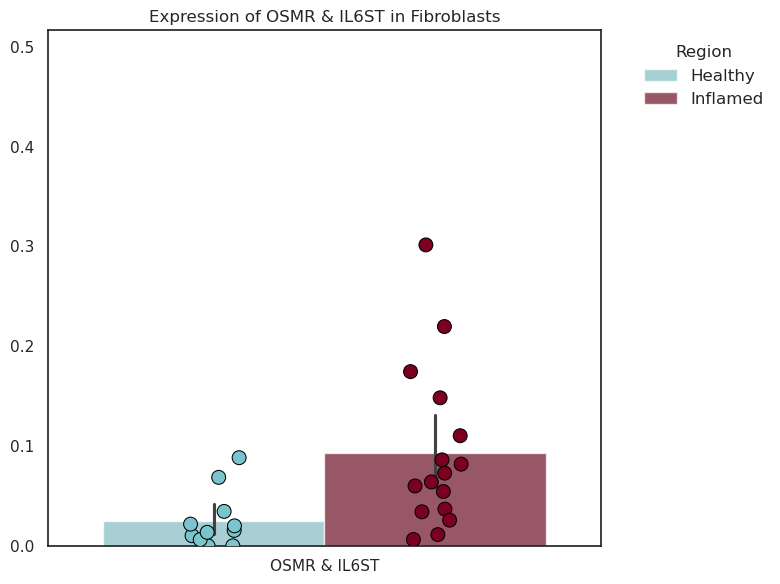

In [17]:
# Bar chart: combined expression, normalized by cell type
sns.set(style="white")
plt.figure(figsize=(8, 6))

ax2 = sns.barplot(x='variable', y='value', hue='region', data=celltype_data_combined,
                  alpha=0.7, palette=palette_custom)
add_stripplot(ax2, celltype_data_combined, dot_size=10)
adjust_y_axis(ax2)

# Legend outside the plot to the right
handles2, labels2 = ax2.get_legend_handles_labels()
ax2.legend_.remove()
ax2.legend(handles2[:2], labels2[:2], loc='upper left', bbox_to_anchor=(1.05, 1),
           title="Region", frameon=False, fontsize='medium')

plt.title(f"Expression of {gene1} & {gene2} in {celltype}")
ax2.set_xticks([0], labels=[f'{gene1} & {gene2}'])
ax2.set_xlabel('')
ax2.set_ylabel('')
plt.tight_layout()
plt.show()

## Supplemental Figure 4c

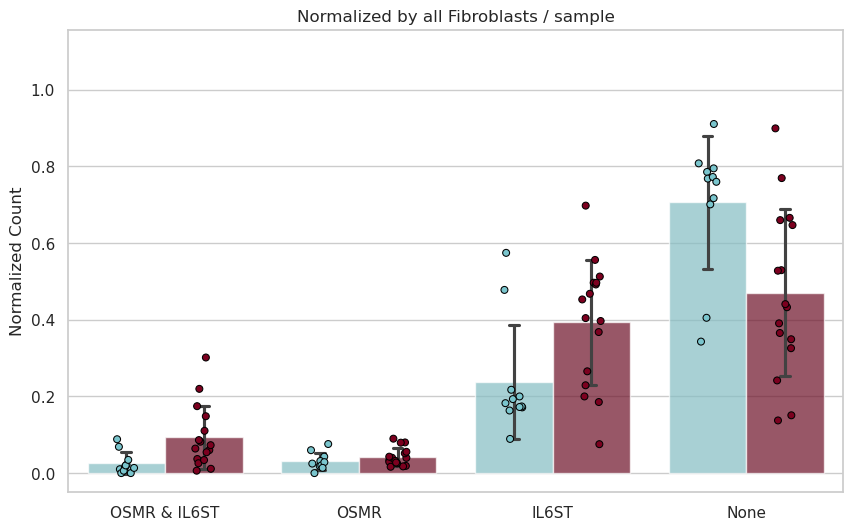

In [18]:
# Bar chart: all categories, normalized by cell type
sns.set(style="whitegrid")
plt.figure(figsize=(10, 6))

ax2 = sns.barplot(x='variable', y='value', hue='region', data=celltype_data, alpha=0.7,
                  palette=palette_custom, errorbar='sd', capsize=0.1)
add_stripplot(ax2, celltype_data, dot_size=5)
ax2.set_xticks(range(len(custom_labels)), labels=custom_labels)
ax2.set_xlabel('')
ax2.set_ylabel('Normalized Count')
plt.title(f"Normalized by all {celltype} / sample")
ax2.legend_.remove()
adjust_y_axis(ax2)
plt.show()

In [19]:
# Welch's t-tests (Healthy vs Inflamed) with Bonferroni correction
numeric_columns_1 = [f"counts_{gene1}_norm_sample", f"counts_{gene2}_norm_sample", "counts_both_norm_sample", "counts_none_norm_sample"]
numeric_columns_2 = [f"counts_{gene1}", f"counts_{gene2}", "counts_both", "counts_none"]
numeric_columns_3 = [f"counts_{gene1}_norm_{celltype}", f"counts_{gene2}_norm_{celltype}", f"counts_both_norm_{celltype}", f"counts_none_norm_{celltype}"]


def perform_ttests_and_adjust(cell_counts, numeric_columns):
    p_values = []
    for col_name in numeric_columns:
        group1 = cell_counts[cell_counts['region'] == 'Healthy'][col_name]
        group2 = cell_counts[cell_counts['region'] == 'Inflamed'][col_name]
        t_stat, p_value = ttest_ind(group1, group2, equal_var=False, nan_policy='omit')
        p_values.append(p_value)

    adjusted_p_values = multi.multipletests(p_values, method='bonferroni')[1]

    return pd.DataFrame({
        'Column': numeric_columns,
        'p_value': p_values,
        'adjusted_p_value': adjusted_p_values
    })


results_1 = perform_ttests_and_adjust(cell_counts, numeric_columns_1)
results_2 = perform_ttests_and_adjust(cell_counts, numeric_columns_2)
results_3 = perform_ttests_and_adjust(cell_counts, numeric_columns_3)
combined_results = pd.concat([results_2, results_1, results_3]).reset_index(drop=True)
combined_results

,Column,p_value,adjusted_p_value
0,counts_OSMR,0.224909,0.899635
1,counts_IL6ST,0.313445,1.000000
2,counts_both,0.050177,0.200707
3,counts_none,0.308813,1.000000
4,counts_OSMR_norm_sample,0.294175,1.000000
5,counts_IL6ST_norm_sample,0.099655,0.398619
6,counts_both_norm_sample,0.017039,0.068156
7,counts_none_norm_sample,0.662373,1.000000
8,counts_OSMR_norm_Fibroblasts,0.191114,0.764457
9,counts_IL6ST_norm_Fibroblasts,0.016767,0.067069


## Figure 2h / Supplemental Figure 4e

In [20]:
def normalize_to_range(row):
    min_val = row.min()
    max_val = row.max()
    range_val = max_val - min_val
    if range_val == 0:
        return row
    return 2 * ((row - min_val) / range_val) - 1

In [21]:
# Gene sets and compartments
vascular_genes = ['NOS3', 'MAPK3', 'KDR', 'FLT1']
stem_genes = ['VEGFA', 'EPAS1', 'CREBBP', 'EP300', 'ARNT', 'HIF1A',
              'EGLN3', 'EGLN2', 'EGLN1']

Stromal = ["Fibroblasts", "Vascular"]
Epithelial = ["Stem and multipotent cells", "Enterocytes", "M cells", "Goblet", "Tuft"]


def mean_expression_per_sample(hm_celltype, hm_genes):
    hm_cells = cells[cells['cell_type'] == hm_celltype]
    hm_counts = counts.loc[hm_genes, hm_cells['cell_ID']]
    merged_df = pd.merge(hm_cells, hm_counts.T, left_on='cell_ID', right_index=True)
    return merged_df.groupby('sample_ID')[hm_genes].mean()


def celltype_fraction_in_compartment(hm_celltype, compartment):
    celltype_per_sample = (cells[cells['cell_type'] == hm_celltype]
                           .groupby('sample_ID').size())
    compartment_per_sample = (cells[cells['cell_type'].isin(compartment)]
                              .groupby('sample_ID').size())
    return celltype_per_sample.divide(compartment_per_sample, axis=0)

In [22]:
cluster_vascular = mean_expression_per_sample("Vascular", vascular_genes)
cluster_stem = mean_expression_per_sample("Stem and multipotent cells", stem_genes)

cluster_vascular_normalized = cluster_vascular.apply(normalize_to_range, axis=0)
cluster_stem_normalized = cluster_stem.apply(normalize_to_range, axis=0)

new_active_frac_stromal = celltype_fraction_in_compartment("Vascular", Stromal)
new_active_frac_epi = celltype_fraction_in_compartment("Stem and multipotent cells",
                                                       Epithelial)

merged_clusters_norm = pd.merge(cluster_vascular_normalized, cluster_stem_normalized,
                                left_index=True, right_index=True)

merged_cluster_ct_per_cohort = pd.DataFrame(index=new_active_frac_epi.index)
for gene in vascular_genes:
    merged_cluster_ct_per_cohort[gene] = new_active_frac_stromal
for gene in stem_genes:
    merged_cluster_ct_per_cohort[gene] = new_active_frac_epi

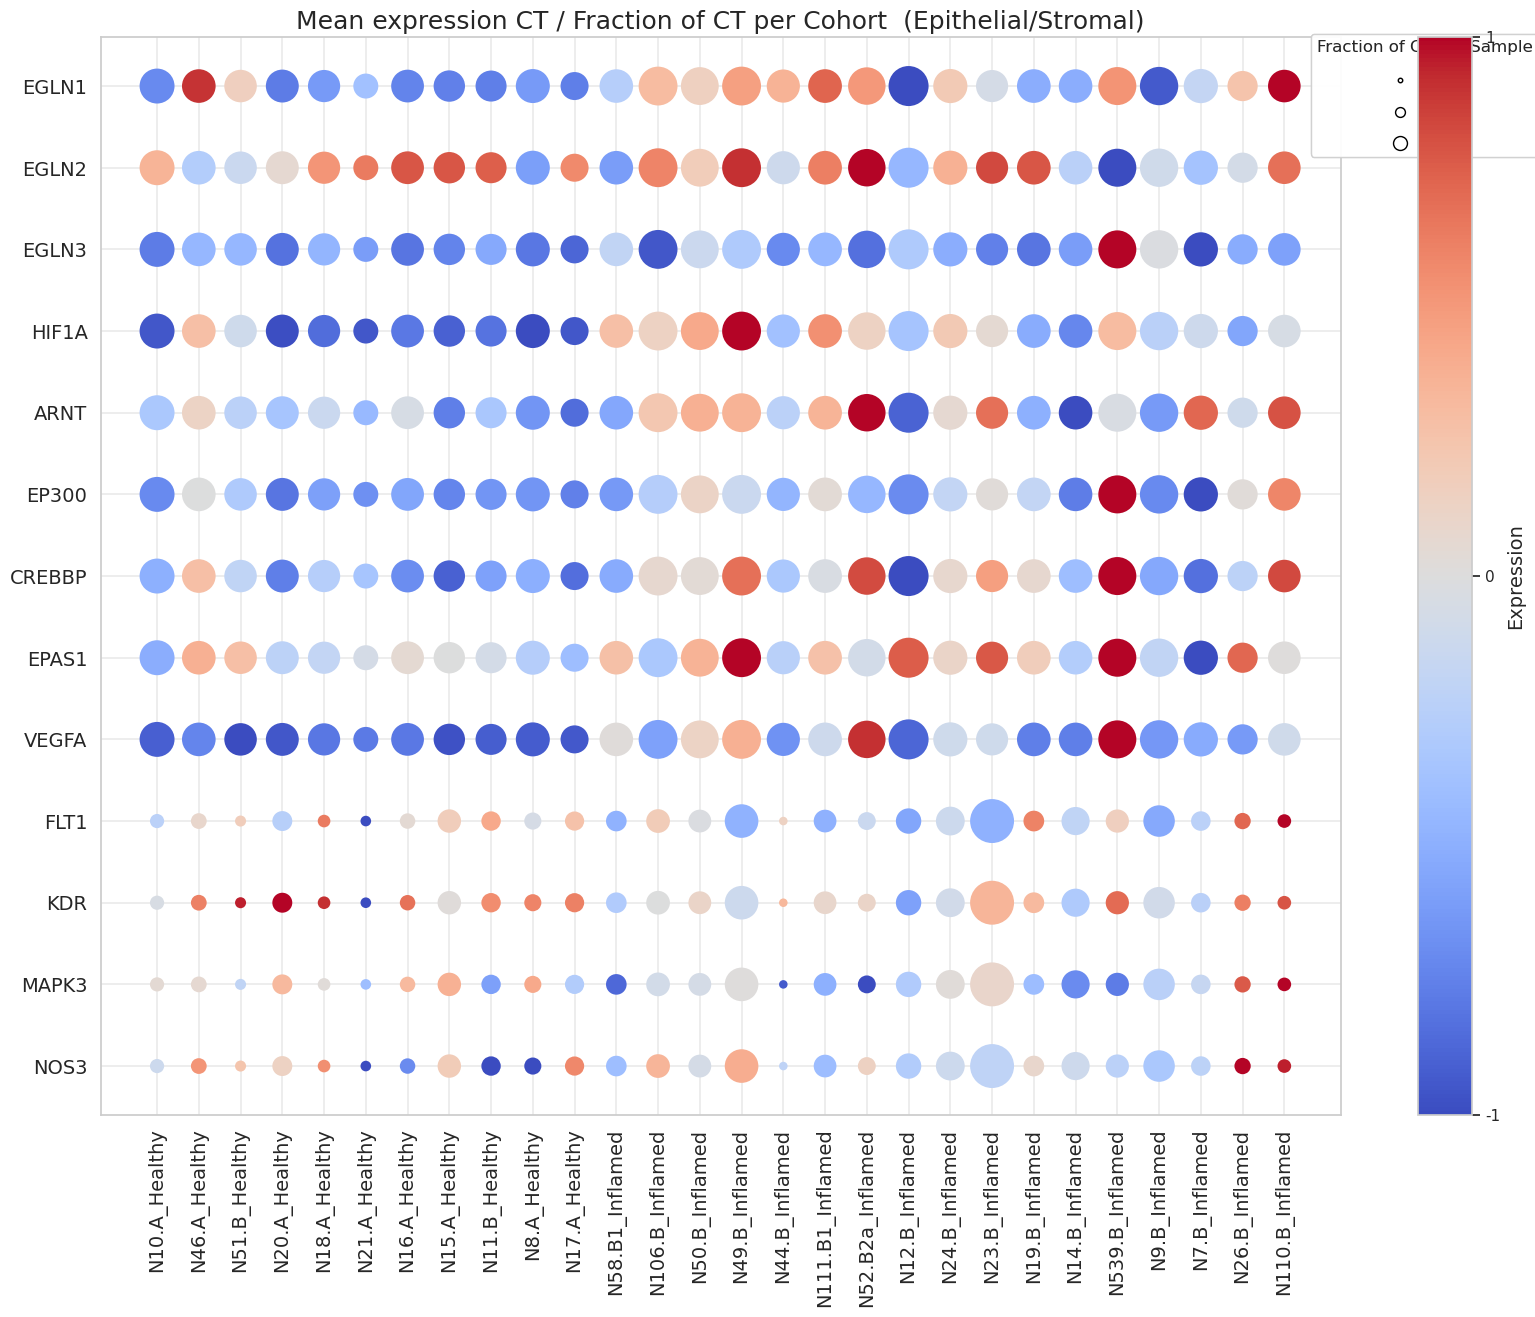

In [23]:
# Dot plot: color = scaled mean expression per gene, size = cell type fraction in compartment
ordered_genes = vascular_genes + stem_genes

unique_cells = cells.drop_duplicates(subset=['sample_ID'])
sorted_cells = unique_cells.sort_values(
    'health_status', key=lambda x: x.map({'Healthy': 1, 'Colitis': 2}))
sorted_indices = sorted_cells['sample_ID']

merged_clusters_norm_sorted = merged_clusters_norm.loc[sorted_indices, ordered_genes]
merged_clusters_act_sorted = merged_cluster_ct_per_cohort.loc[sorted_indices, ordered_genes]

fig, ax = plt.subplots(figsize=(20, 14))
ax.set_facecolor('white')
ax.grid(True, linestyle='-', linewidth='0.2', color='grey')

for j, sample in enumerate(merged_clusters_norm_sorted.index):
    for i, gene in enumerate(merged_clusters_norm_sorted.columns):
        size = merged_clusters_act_sorted.loc[sample, gene] * 1000
        color_val = merged_clusters_norm_sorted.loc[sample, gene]
        ax.scatter(j, i, s=size, c=[cm.coolwarm((color_val + 1) / 2)], edgecolors='none')

ax.set_yticks(np.arange(len(ordered_genes)))
ax.set_yticklabels(ordered_genes, fontsize=14)
ax.set_xticks(np.arange(len(merged_clusters_norm_sorted.index)))
ax.set_xticklabels(merged_clusters_norm_sorted.index, rotation=90, fontsize=14)

size_legend = [plt.scatter([], [], s=i * 1000, edgecolors='black', color='white')
               for i in [0.01, 0.05, 0.1]]
size_legend = plt.legend(size_legend, ['1%', '5%', '10%'],
                         title="Fraction of CT per Sample", loc='upper left',
                         bbox_to_anchor=(0.97, 1.01), labelspacing=1.1, handletextpad=1)
ax.add_artist(size_legend)

cbar = plt.colorbar(cm.ScalarMappable(cmap='coolwarm'), ax=ax,
                    orientation='vertical', ticks=[0, 0.5, 1])
cbar.set_label('Expression', fontsize=14)
cbar.set_ticklabels(['-1', '0', '1'])
plt.title('Mean expression CT / Fraction of CT per Cohort  (Epithelial/Stromal)',
          fontsize=18)
plt.show()